# 06: Daraxtga asoslangan modellar
Maqsad: Decision Tree, Random Forest va Gradient Boosting bilan tanishish
va ularni linear modellar bilan solishtirish.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, r2_score

df = sns.load_dataset("mpg").dropna()
features = ["weight", "horsepower", "displacement", "cylinders", "model_year"]
X = df[features]
y = df["mpg"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
Mashq 1: Decision Tree qanday "o'ylaydi"?

📖 Izoh: Linear regression formula (y' = b + wx) bilan ishlaydi. Decision Tree esa savollar zanjiri bilan ishlaydi, xuddi "20 ta savol" o'yinidagidek:

Dvigatel hajmi ≤ 198.5 mi?
   ├── Ha  → Ot kuchi ≤ 84.5 mi?
   │          ├── Ha  → ~32 mpg
   │          └── Yo'q → ~25 mpg
   └── Yo'q → Ot kuchi ≤ 127 mi?
              ├── Ha  → ~19 mpg
              └── Yo'q → ~15 mpg

Daraxt har bir qadamda ma'lumotni ikkiga bo'ladigan eng yaxshi savolni o'zi tanlaydi. Oxirgi "barg"dagi bashorat esa o'sha guruhga tushgan mashinalarning o'rtacha mpg qiymati bo'ladi.

💡 Muhim farq: daraxtlarga StandardScaler kerak emas! Ular faqat "≤ mi?" degan savollar beradi, shuning uchun masshtab ahamiyatga ega emas.

Kichik daraxtni (max_depth=2, ya'ni 2 qavat savol) chizib ko'ramiz:

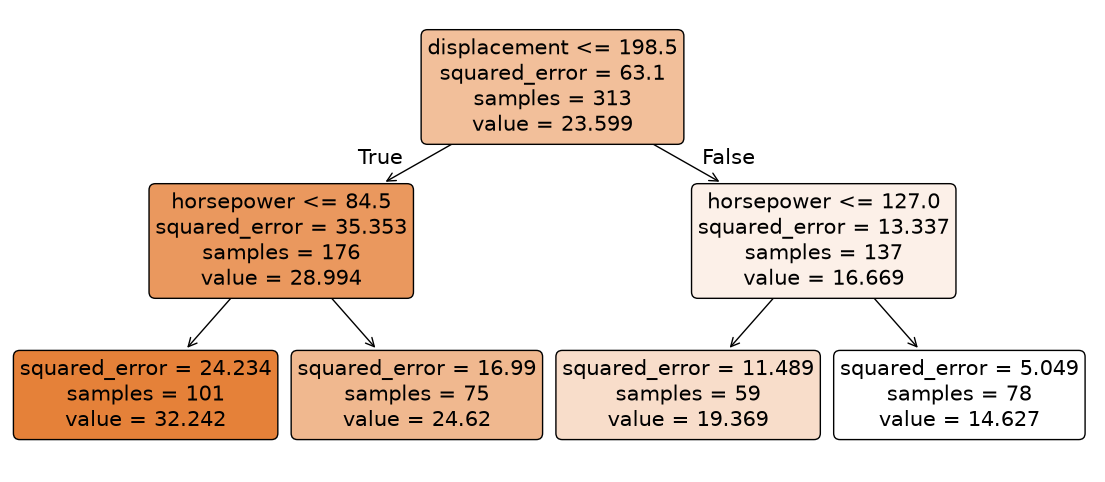

In [2]:
small_tree = DecisionTreeRegressor(max_depth=2, random_state=42)
small_tree.fit(X_train, y_train)

plt.figure(figsize=(14, 6))
plot_tree(small_tree, feature_names=features, filled=True, rounded=True)
plt.show()

Mashq 2: Decision Tree va Overfitting

📖 Izoh: max_depth daraxtning chuqurligi, ya'ni ketma-ket nechta savol berishi mumkinligini belgilaydi. Bu hyperparameter 05-notebookdagi degree ga o'xshaydi: qanchalik katta bo'lsa, model shunchalik murakkab bo'ladi.

In [3]:
for depth in [1, 2, 3, 5, 10, None]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    tree.fit(X_train, y_train)

    train_r2 = r2_score(y_train, tree.predict(X_train))
    test_r2  = r2_score(y_test,  tree.predict(X_test))
    print(f"max_depth={str(depth):<5} train R²={train_r2:.3f}  test R²={test_r2:.3f}")

max_depth=1     train R²=0.592  test R²=0.489
max_depth=2     train R²=0.757  test R²=0.583
max_depth=3     train R²=0.840  test R²=0.733
max_depth=5     train R²=0.929  test R²=0.750
max_depth=10    train R²=0.995  test R²=0.718
max_depth=None  train R²=0.999  test R²=0.695


Mashq 3: Random Forest, ya'ni ko'p daraxtlar "kengashi"

📖 Izoh: Bitta daraxt xato qilishi mumkin. Lekin yuzlab daraxt ovoz bersa-chi?

Random Forest:

Ko'p daraxt yaratadi (n_estimators ta)
Har bir daraxt ma'lumotning tasodifiy qismida va tasodifiy feature'lar bilan o'qitiladi, shuning uchun hamma daraxtlar bir-biridan farq qiladi
Yakuniy bashorat barcha daraxtlar javobining o'rtachasi bo'ladi

👥 Analogiya: "Kim millioner bo'lishni xohlaydi" o'yinidagi "zaldan yordam". Bitta odam xato qilishi mumkin, lekin 100 kishining o'rtacha javobi odatda juda aniq bo'ladi. Har kimning xatosi har xil, shuning uchun o'rtachalanganda ular bir-birini yo'qqa chiqaradi.

In [4]:
for n in [10, 100, 300]:
    rf = RandomForestRegressor(n_estimators=n, random_state=42)
    rf.fit(X_train, y_train)

    train_r2 = r2_score(y_train, rf.predict(X_train))
    test_r2  = r2_score(y_test,  rf.predict(X_test))
    print(f"n_estimators={n:<4} train R²={train_r2:.3f}  test R²={test_r2:.3f}")

n_estimators=10   train R²=0.970  test R²=0.837
n_estimators=100  train R²=0.980  test R²=0.873
n_estimators=300  train R²=0.981  test R²=0.878


Mashq 4: Gradient Boosting, ya'ni xatolardan o'rganadigan daraxtlar

📖 Izoh: Random Forest'da daraxtlar bir-biridan mustaqil, parallel ravishda quriladi. Gradient Boosting'da esa ular ketma-ket quriladi va har bir yangi daraxt oldingilarning xatosini tuzatishga harakat qiladi:

1-daraxt: bashorat qiladi           → xatolar qoladi
2-daraxt: 1-daraxtning xatosini o'rganadi  → kichikroq xatolar
3-daraxt: qolgan xatoni o'rganadi    → yanada kichikroq
...
Yakuniy bashorat = barcha daraxtlar yig'indisi

🎯 Analogiya: golf o'yini. 1-zarba to'pni teshik tomonga uzoqqa uradi, keyingi har bir zarba esa qolgan masofani tuzatadi.

Nomidagi "Gradient" so'zi tasodifiy emas: bu jarayon biz o'rgangan gradient descent g'oyasiga asoslanadi. Shuning uchun bu yerda ham tanish hyperparameter bor: learning_rate!

In [5]:
for lr, n in [(0.1, 100), (0.05, 300), (1.0, 100)]:
    gb = GradientBoostingRegressor(n_estimators=n, learning_rate=lr, random_state=42)
    gb.fit(X_train, y_train)

    train_r2 = r2_score(y_train, gb.predict(X_train))
    test_r2  = r2_score(y_test,  gb.predict(X_test))
    print(f"learning_rate={lr:<5} n_estimators={n:<4} train R²={train_r2:.3f}  test R²={test_r2:.3f}")

learning_rate=0.1   n_estimators=100  train R²=0.965  test R²=0.871
learning_rate=0.05  n_estimators=300  train R²=0.974  test R²=0.874
learning_rate=1.0   n_estimators=100  train R²=0.999  test R²=0.714


Mashq 5: Katta bellashuv 🏆 + Feature Importance

📖 Izoh: 03–06 notebooklardagi barcha eng yaxshi modellarni bir xil sharoitda solishtiramiz: bir xil train/test bo'linishi va cross-validation.

In [6]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Poly(2) + Ridge":   make_pipeline(StandardScaler(), PolynomialFeatures(2), Ridge(alpha=10)),
    "Decision Tree":     DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cv_r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2").mean()
    rows.append([name, mean_absolute_error(y_test, y_pred), r2_score(y_test, y_pred), cv_r2])

results = pd.DataFrame(rows, columns=["Model", "Test MAE", "Test R²", "CV R²"])
results.round(3).sort_values("Test R²", ascending=False)

,Model,Test MAE,Test R²,CV R²
3,Random Forest,1.795,0.878,0.861
4,Gradient Boosting,1.829,0.874,0.852
1,Poly(2) + Ridge,1.891,0.868,0.865
0,Linear Regression,2.502,0.793,0.805
2,Decision Tree,2.531,0.750,0.789


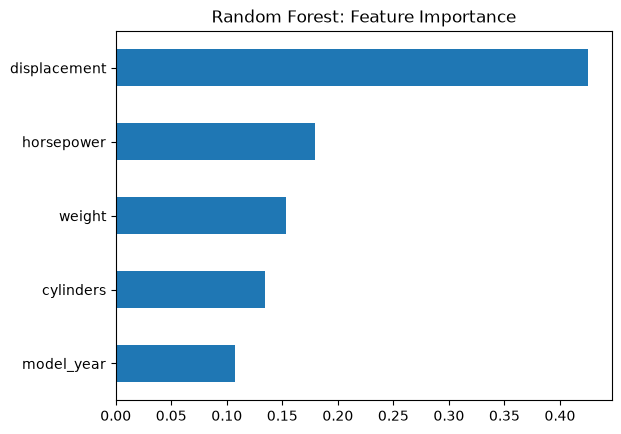

In [7]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=features).sort_values()

importance.plot(kind="barh")
plt.title("Random Forest: Feature Importance")
plt.show()